**«Удержит ли штат партия действующего президента»** . Так устроена известная модель «Time for Change» политолога Алана Абрамовица. Для модели Рейган-1984 и Клинтон-1996 — одна и та же ситуация («президент идёт на второй срок»), и ей хватает ~12 выборов для обучения. 

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DEM, GRAY = "#2a78d6", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
})

results = pd.read_csv("../data/processed/state_results.csv")  # из ноутбука 01
results.head()

,year,state,dem_votes,rep_votes,dem_share,dem_win
0,1976,AK,44058,71555,0.381082,0
1,1976,AL,659170,504070,0.566667,1
2,1976,AR,498604,267903,0.650489,1
3,1976,AZ,295602,418642,0.413867,0
4,1976,CA,3742284,3882244,0.490822,0


* `incumbent` — партия президента в год выборов;
* `inc_running` — идёт ли сам президент на второй срок;
* `inc_long_tenure` — партия у власти уже 2+ срока подряд (избиратели устают: «пора менять»);
* `dem_home`, `rep_home` — родные штаты кандидатов.

In [2]:
elections = pd.DataFrame([
    # год, партия президента, идёт ли сам, 2+ срока у власти, родной штат D, родной штат R
    (1980, "D", 1, 0, "GA", "CA"),    # Carter vs Reagan
    (1984, "R", 1, 0, "MN", "CA"),    # Mondale vs Reagan
    (1988, "R", 0, 1, "MA", "TX"),    # Dukakis vs Bush
    (1992, "R", 1, 1, "AR", "TX"),    # Clinton vs Bush (республиканцы у власти с 1981)
    (1996, "D", 1, 0, "AR", "KS"),    # Clinton vs Dole
    (2000, "D", 0, 1, "TN", "TX"),    # Gore vs Bush
    (2004, "R", 1, 0, "MA", "TX"),    # Kerry vs Bush
    (2008, "R", 0, 1, "IL", "AZ"),    # Obama vs McCain
    (2012, "D", 1, 0, "IL", "MA"),    # Obama vs Romney
    (2016, "D", 0, 1, "NY", "NY"),    # Clinton vs Trump
    (2020, "R", 1, 0, "DE", "FL"),    # Biden vs Trump
    (2024, "D", 0, 0, "CA", "FL"),    # Harris vs Trump (Байден снялся)
    (2028, "R", 0, 0, None, None),    # прогноз: Трамп не может идти на 3-й срок
], columns=["year", "incumbent", "inc_running", "inc_long_tenure", "dem_home", "rep_home"])


1. **Результат 4 года назад.** `shift(1)` внутри каждого штата берёт значение с прошлых выборов.
2. **«Отклонение» штата** (`lean`) — насколько штат голосовал левее (+) или правее (−) страны в целом.
3. **Разворот «к партии власти».** Если президент — республиканец, доля партии власти = 1 − доля демократов, знаки меняются на противоположные.


In [3]:
national = results.groupby("year")[["dem_votes", "rep_votes"]].sum()
results["dem_lean"] = results.dem_share - results.year.map(national.dem_votes / national.sum(axis=1))

future = pd.DataFrame({"year": 2028, "state": results.state.unique()})
df = pd.concat([results, future]).sort_values(["state", "year"])
df["prev_dem_share"] = df.groupby("state").dem_share.shift(1)
df["prev_dem_lean"] = df.groupby("state").dem_lean.shift(1)
df = df.merge(elections, on="year")  # 1976 отпадает: для него нет прошлых выборов

sign = np.where(df.incumbent == "D", 1, -1)  # +1 президент-демократ, −1 республиканец
df["inc_prev_share"] = np.where(sign == 1, df.prev_dem_share, 1 - df.prev_dem_share)
df["inc_prev_lean"] = sign * df.prev_dem_lean
home = (df.state == df.dem_home).astype(int) - (df.state == df.rep_home).astype(int)
df["inc_home_state"] = sign * home
df["inc_win"] = np.where(sign == 1, df.dem_win, 1 - df.dem_win)  # то, что предсказываем

FEATURES = ["inc_prev_share", "inc_prev_lean", "inc_running", "inc_long_tenure", "inc_home_state"]
TARGET = "inc_win"

df[["year", "state", "incumbent", *FEATURES, TARGET]].query("state == 'PA'")

,year,state,incumbent,inc_prev_share,inc_prev_lean,inc_running,inc_long_tenure,inc_home_state,inc_win
494,1980,PA,D,0.513571,0.003067,1,0,0,0.0
495,1984,PA,R,0.538616,-0.014406,1,0,0,1.0
496,1988,PA,R,0.537007,-0.054746,0,1,0,1.0
497,1992,PA,R,0.511695,-0.027320,1,1,0,0.0
498,1996,PA,D,0.555485,0.020685,1,0,0,1.0
499,2000,PA,D,0.551612,0.004248,0,1,0,1.0
500,2004,PA,R,0.478515,-0.018824,1,0,0,0.0
501,2008,PA,R,0.487417,-0.024975,0,1,0,0.0
502,2012,PA,D,0.552297,0.015409,1,0,0,1.0
503,2016,PA,D,0.527319,0.007736,0,1,0,0.0


In [4]:
df[["year", "state", "incumbent", *FEATURES, "dem_share", "dem_win", TARGET]].to_csv(
    "../data/processed/state_features.csv", index=False)

data = df.dropna(subset=[TARGET]).copy()  # для обучения — только выборы с известным результатом
data[TARGET] = data[TARGET].astype(int)
data["dem_win"] = data.dem_win.astype(int)
print(f"{len(data)} строк: {data.year.nunique()} выборов ({data.year.min()}–{data.year.max()}) × 51 штат")

612 строк: 12 выборов (1980–2024) × 51 штат


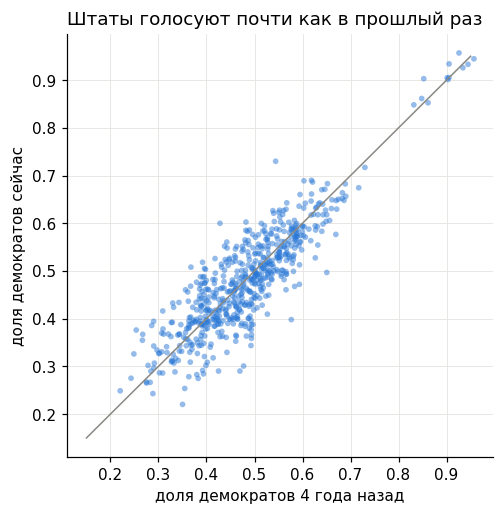

корреляция: 0.88


In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(data.prev_dem_share, data.dem_share, s=14, alpha=0.5, color=DEM, edgecolors="none")
ax.plot([0.15, 0.95], [0.15, 0.95], color=GRAY, lw=1)
ax.set(xlabel="доля демократов 4 года назад", ylabel="доля демократов сейчас")
ax.set_title("Штаты голосуют почти как в прошлый раз", loc="left")
plt.show()
print("корреляция:", round(data.prev_dem_share.corr(data.dem_share), 3))

baseline - штат проголосует так же как в прошлый при корр 0.88


* **accuracy** — доля штатов, где угадан победитель;
* **log loss** — штраф за ошибки

In [6]:
TEST_YEARS = [1996, 2000, 2004, 2008, 2012, 2016, 2020, 2024]  # 1980–1992 — только для обучения


def backtest(model, data, features, target):
    """Для каждого года T: учимся на выборах до T, предсказываем T."""
    parts = []
    for year in TEST_YEARS:
        train, test = data[data.year < year], data[data.year == year]
        fitted = clone(model).fit(train[features], train[target])
        parts.append(test.assign(proba=fitted.predict_proba(test[features])[:, 1]))
    return pd.concat(parts)


def evaluate(pred, target):
    return pd.Series({
        "accuracy": accuracy_score(pred[target], pred.proba > 0.5),
        "log_loss": log_loss(pred[target], pred.proba.clip(0.01, 0.99)),
    })

In [7]:
models = {
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "gradient_boosting": GradientBoostingClassifier(n_estimators=150, max_depth=2,
                                                    learning_rate=0.05, random_state=42),
}

test = data[data.year.isin(TEST_YEARS)]
predictions = {"baseline": test.assign(proba=(test.inc_prev_share > 0.5).astype(float))}
for name, model in models.items():
    predictions[name] = backtest(model, data, FEATURES, TARGET)

scores = pd.DataFrame({name: evaluate(pred, TARGET) for name, pred in predictions.items()}).T
scores.round(3)

,accuracy,log_loss
baseline,0.885,0.539
logistic_regression,0.902,0.247
random_forest,0.904,0.265
gradient_boosting,0.887,0.272


In [ ]:
# точность по годам
pd.DataFrame({
    name: (pred.proba > 0.5).eq(pred[TARGET]).groupby(pred.year).mean()
    for name, pred in predictions.items()
}).round(2)

,baseline,logistic_regression,random_forest,gradient_boosting
year,,,,
1996,0.90,0.90,0.78,0.78
2000,0.78,0.84,0.88,0.84
2004,0.94,0.86,0.84,0.84
2008,0.82,0.92,0.94,0.92
2012,0.96,0.98,0.96,0.96
2016,0.88,0.88,0.90,0.84
2020,0.90,0.96,0.96,0.94
2024,0.88,0.86,0.96,0.96


In [9]:
best = scores.loc[list(models), "log_loss"].idxmin()
pred = predictions[best]
pred["proba_dem"] = np.where(pred.incumbent == "D", pred.proba, 1 - pred.proba)
errors = pred[(pred.proba_dem > 0.5) != (pred.dem_win == 1)]
print("лучшая модель:", best, "\n")
for year, group in errors.groupby("year"):
    print(year, ", ".join(f"{r.state} ({r.proba_dem:.2f})" for r in group.itertuples()))

лучшая модель: logistic_regression 

1996 AZ (0.37), CO (0.59), FL (0.37), MT (0.53), NH (0.48)
2000 AR (0.66), IA (0.42), NM (0.32), OR (0.36), PA (0.39), TN (0.88), WI (0.44), WV (0.60)
2004 FL (0.69), IA (0.70), MO (0.57), NM (0.69), NV (0.56), OH (0.56), TN (0.56)
2008 AR (0.64), IN (0.22), MO (0.73), WV (0.51)
2012 IN (0.51)
2016 CO (0.25), MN (0.34), NH (0.25), NM (0.46), NV (0.30), VA (0.20)
2020 AZ (0.40), GA (0.33)
2024 AZ (0.69), GA (0.69), MI (0.79), NC (0.62), NV (0.77), PA (0.73), WI (0.71)


ошибки — Аризона, Джорджия, Пенсильвания, Висконсин…, где результат решают 1–2%. Хуже  модель справилась с 2000, 2004 и 2024 годами: общенациональная волна оказалась не такой, как она ожидала 


In [ ]:
# признаки со знаком «+ в пользу D», цель — `dem_win`.
sign_d = np.where(data.incumbent == "D", 1, -1)  # +1 президент-демократ, −1 республиканец
dem_view = data.assign(
    incumbent_dem=sign_d,
    running_dem=sign_d * data.inc_running,
    long_tenure_dem=sign_d * data.inc_long_tenure,
    home_state_dem=sign_d * data.inc_home_state,
)
DEM_FEATURES = ["prev_dem_share", "prev_dem_lean", "incumbent_dem", "running_dem",
                "long_tenure_dem", "home_state_dem"]

dem_scores = pd.DataFrame({
    name: evaluate(backtest(model, dem_view, DEM_FEATURES, "dem_win"), "dem_win")
    for name, model in models.items()
}).T
pd.concat({"выиграют ли D": dem_scores, "удержит ли партия власти": scores.loc[list(models)]},
          axis=1).round(3)

выиграют ли D          удержит ли партия власти         
                         accuracy log_loss                 accuracy log_loss
logistic_regression         0.806    0.443                    0.902    0.247
random_forest               0.843    0.370                    0.904    0.265
gradient_boosting           0.831    0.375                    0.887    0.272

до 1996 года президенты были в основном республиканцами, и модели приходится учить как ведут себя избиратели при демократе и республиканце.

Мы также пробовали добавить рост ВВП — модель стала хуже: из-за COVID в 2020 году ВВП упал на 28%, и этот выброс сбивает модель, обученную на 12 выборах.


In [11]:
final_model = clone(models[best]).fit(data[FEATURES], data[TARGET])
joblib.dump(final_model, "../model.joblib")
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['inc_prev_share','inc_prev_lean','inc_running','inc_long_tenure', 'inc_home_state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


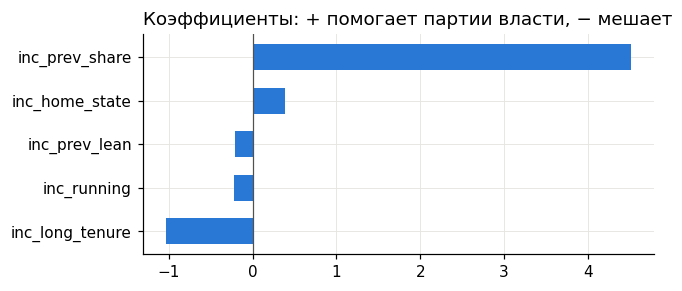

inc_long_tenure   -1.04
inc_running       -0.22
inc_prev_lean     -0.21
inc_home_state     0.39
inc_prev_share     4.51
dtype: float64

In [12]:
# коэффициенты логистической регрессии (признаки стандартизированы, поэтому их можно сравнивать)
coefs = pd.Series(final_model[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(coefs.index, coefs.values, color=DEM, height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_title("Коэффициенты: + помогает партии власти, − мешает", loc="left")
plt.show()
coefs.round(2)

* `inc_prev_share` — прошлый результат партии в штате
* `inc_long_tenure` — если партия правит 2+ срока, избиратели хотят перемен
* `inc_home_state` — родной штат кандидата


In [13]:
model = joblib.load("../model.joblib")
print("модель ждёт признаки:", list(model.feature_names_in_))

# Штат, где партия власти в прошлый раз набрала 52%, президент идёт на второй срок
example = pd.DataFrame([{"inc_prev_share": 0.52, "inc_prev_lean": 0.0, "inc_running": 1,
                         "inc_long_tenure": 0, "inc_home_state": 0}])
print("вероятность, что партия власти удержит штат:", model.predict_proba(example)[0, 1].round(3))

модель ждёт признаки: ['inc_prev_share', 'inc_prev_lean', 'inc_running', 'inc_long_tenure', 'inc_home_state']
вероятность, что партия власти удержит штат: 0.57


## Прогноз на 2028 год 

In [14]:
forecast = df[df.year == 2028].copy()
proba_inc = model.predict_proba(forecast[FEATURES])[:, 1]
forecast["proba_dem"] = np.where(forecast.incumbent == "D", proba_inc, 1 - proba_inc)

print("штатов за демократов:", (forecast.proba_dem > 0.5).sum(), "из 51")
forecast.query("0.3 < proba_dem < 0.7").sort_values("proba_dem")[["state", "proba_dem"]].round(2)

штатов за демократов: 20 из 51


,state,proba_dem
363,NC,0.37
441,NV,0.37
142,GA,0.42
506,PA,0.44
298,MI,0.45
636,WI,0.48
402,NH,0.67
